# Data import

In [3]:
# Dependencies
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, roc_auc_score
from data_engineering import make_splits, load_raw, clean, build_features

In [4]:
# Load data
raw_data = load_raw()
df = clean(raw_data)
out = make_splits(df)

In [5]:
data = []
for ts, (X_tr, X_te, y_tr, y_te, info) in out.items():
        data.append((ts, X_tr, X_te, y_tr, y_te, info))
        print(f"test={ts:.0%} -> train {X_tr.shape}, test {X_te.shape}, "
              f"%>50K train={y_tr.mean():.3f} test={y_te.mean():.3f}")

test=10% -> train (43911, 88), test (4879, 88), %>50K train=0.239 test=0.239
test=20% -> train (39032, 88), test (9758, 88), %>50K train=0.239 test=0.239
test=30% -> train (34153, 88), test (14637, 88), %>50K train=0.239 test=0.239
test=40% -> train (29274, 88), test (19516, 88), %>50K train=0.239 test=0.239


# Deep Neural Network

The size of the neural network would be 88-4-2-1

In [6]:
def relu(z):
    return np.maximum(0, z)

def relu_derivative(z):
    return (z > 0).astype(float)

In [7]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def sigmoid_derivative(z):
    s = sigmoid(z)
    return s * (1 - s)

In [8]:
def BCE(Y, Y_HAT):
    N = len(Y)
    return -1/N * np.sum(Y * np.log(Y_HAT) + (1 - Y) * np.log(1 - Y_HAT))

In [9]:
def forward(X, W1, b1, W2, b2, W3, b3):
    # Layer 1
    Z1 = np.dot(X, W1) + b1
    A1 = relu(Z1)
    
    # Layer 2
    Z2 = np.dot(A1, W2) + b2
    A2 = relu(Z2)
    
    # Output layer
    Z3 = np.dot(A2, W3) + b3
    A3 = sigmoid(Z3)
    
    return Z1, A1, Z2, A2, Z3, A3

In [10]:
def backpropagation(A1, A2, A3, Y, X, W3, b3, W2, b2, W1, b1, Z1, Z2, Z3, alpha):
    m = X.shape[0]
    
    # Layer 1
    dZ3 = A3-Y
    dW3 = (A2.T @ dZ3) / m
    db3 = np.sum(dZ3, axis=0, keepdims=True) / m

    # Layer 2
    dZ2 = (dZ3 @ W3.T) * relu_derivative(Z2)
    dW2 = (A1.T @ dZ2) / m
    db2 = np.sum(dZ2, axis=0, keepdims=True) / m

    # Layer 1
    dZ1 = (dZ2 @ W2.T) * relu_derivative(Z1)
    dW1 = (X.T @ dZ1) / m
    db1  = np.sum(dZ1, axis=0, keepdims=True) / m

    # Gradient Descent 
    W3 -= (alpha * dW3)
    b3 -= (alpha * db3)
    W2 -= (alpha * dW2)
    b2 -= (alpha * db2)
    W1 -= (alpha * dW1)
    b1 -= (alpha * db1)
    return W1,b1,W2,b2,W3,b3


In [11]:
def train(df, epochs,alpha):
    # Init the weights and biases
    rng = np.random.default_rng(42)
    X = df[1].to_numpy()
    Y = df[3].to_numpy().reshape(-1, 1)

    # Size of the hidden layers
    h1, h2 = 32, 16

    W1 = rng.standard_normal((X.shape[1], h1)) * np.sqrt(2 / X.shape[1])
    b1 = np.zeros((1, h1))

    W2 = rng.standard_normal((h1, h2)) * np.sqrt(2 / h1)
    b2 = np.zeros((1, h2))

    W3 = rng.standard_normal((h2, 1)) * np.sqrt(1 / h2)
    b3 = np.zeros((1, 1))
    history = []
    for epoch in range(epochs):
        # Forward pass
        Z1, A1, Z2, A2, Z3, A3 = forward(X, W1, b1, W2, b2, W3, b3)
        # Calculate Loss
        loss = BCE(Y, A3)
        # Backpropagation
        W1,b1,W2,b2,W3,b3 = backpropagation(A1, A2, A3, Y, X, W3, b3, W2, b2, W1, b1, Z1, Z2, Z3, alpha)
        history.append(loss)
        #print(f"LookupError: Epoch {epoch+1}/{epochs}, Loss: {loss:.4f}")
    return W1,b1,W2,b2,W3,b3,history

In [12]:
# Train the model
W1,b1,W2,b2,W3,b3,history = train(data[1], epochs=1000, alpha=0.01)
model = (W1,b1,W2,b2,W3,b3)

In [13]:
def graph_loss(history, title="Deep neural network training"):
    plt.plot(history)
    plt.xlabel("Epoch")
    plt.ylabel("loss")
    plt.title(title)
    plt.show()

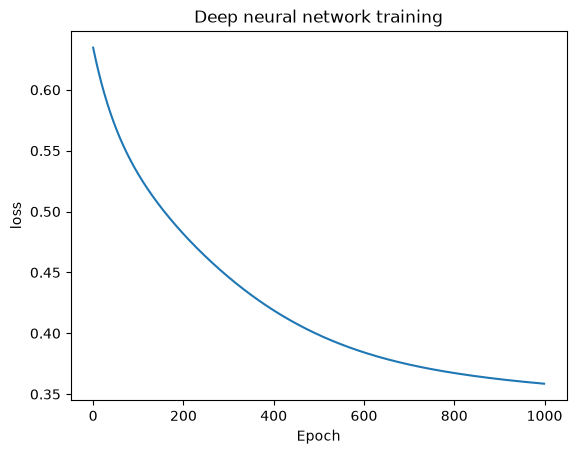

In [14]:
# Display Results
graph_loss(history, title="Deep neural network training")

In [15]:
import json
from pathlib import Path
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

METRICS_FILE = Path("model_metrics.json")

def save_metrics(model, test_size, y_true, y_pred):
    results = (
        json.loads(METRICS_FILE.read_text())
        if METRICS_FILE.exists()
        else {}
    )

    results.setdefault(model, {})[f"{test_size:.0%}"] = {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision": float(precision_score(y_true, y_pred, zero_division=0)),
        "recall": float(recall_score(y_true, y_pred, zero_division=0)),
        "f1_score": float(f1_score(y_true, y_pred, zero_division=0)),
        "samples": int(len(y_true)),
    }

    METRICS_FILE.write_text(json.dumps(results, indent=2))

In [16]:
def evaluate_model(i, data, model):
    X_test = data[i][2].to_numpy()
    Y_test = data[i][4].to_numpy().reshape(-1, 1)

    *_, probabilities = forward(X_test, *model)
    predictions = (probabilities >= 0.4).astype(int)

    print("Test loss:", BCE(Y_test, probabilities))
    print("ROC-AUC:", roc_auc_score(Y_test, probabilities))
    print(classification_report(Y_test, predictions))
    return BCE(Y_test, probabilities)

In [17]:
metrics = evaluate_model(1, data, model)

Test loss: 0.3570795299137145
ROC-AUC: 0.8837490379397792
              precision    recall  f1-score   support

           0       0.90      0.86      0.88      7422
           1       0.61      0.68      0.65      2336

    accuracy                           0.82      9758
   macro avg       0.76      0.77      0.76      9758
weighted avg       0.83      0.82      0.82      9758



In [18]:
for split in data:
    test_size = split[0]
    W1, b1, W2, b2, W3, b3, history = train(
        split, epochs=1000, alpha=0.01
    )
    X_test = split[2].to_numpy()
    y_test = split[4].to_numpy()
    *_, probabilities = forward(X_test, W1, b1, W2, b2, W3, b3)
    y_pred = (probabilities.ravel() >= 0.5).astype(int)
    save_metrics("deep_neural_network", test_size, y_test, y_pred)